# Training Monitor

Live view of the training runs. Run the cell below; it redraws every 10 seconds from the run logs in `logs/` (one file per run):

- **Chart:** train vs validation accuracy and loss of the most recently updated run, epoch by epoch.
- **Table:** recent runs with best validation accuracy, test accuracy (once finished) and status.
- **Last lines** of the newest log.

It only reads files, so it never interferes with training. Click the square stop button to end the loop. Set `LIVE = False` for a single snapshot.


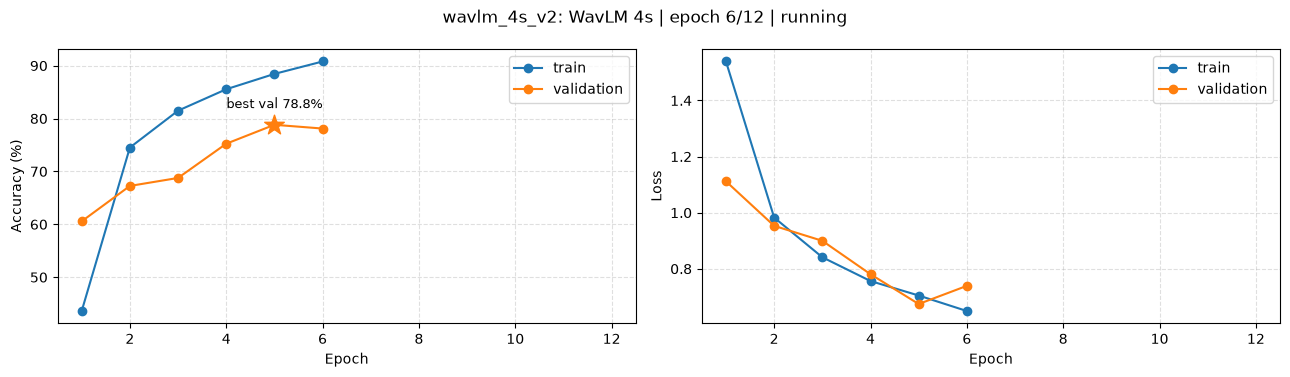

,model,epochs,best val acc %,test acc %,status,updated
run,,,,,,
wavlm_4s_v2,WavLM 4s,6/12,78.8,-,running,10-22 10:36
wavlm_large_v2,WavLM Large,5/12,37.8,37.3,finished,10-22 10:30
wavlm_4s_bal,WavLM 4s balanced,6/12,76.9,78.36,finished,10-22 10:15
wavlm_4s,WavLM 4s,6/12,43.1,42.47,finished,10-22 10:09
train_wavlm_large,WavLM Large,5/12,37.2,36.31,finished,10-22 03:33
train_wavlm_20ep,WavLM,6/20,76.6,77.8,finished,10-22 03:18
train_wavlm_run2,WavLM,12/12,76.7,79.07,finished,10-22 03:12
train_vit_v2,Vision Transformer,12/15,65.9,64.77,finished,10-22 03:02
train_ensemble_v2,3 models (last: Female Emotion Model),30/30,62.6,55.36,finished,10-22 02:48



wavlm_4s_v2.log, last lines (updated 10:37:10):
   Epoch [1/12] - loss: 1.5391 - acc: 0.4361 | val_loss: 1.1118 - val_acc: 0.6057
   Epoch [2/12] - loss: 0.9826 - acc: 0.7452 | val_loss: 0.9531 - val_acc: 0.6726
   Epoch [3/12] - loss: 0.8411 - acc: 0.8149 | val_loss: 0.8997 - val_acc: 0.6877
   Epoch [4/12] - loss: 0.7563 - acc: 0.8554 | val_loss: 0.7806 - val_acc: 0.7524
   Epoch [5/12] - loss: 0.7047 - acc: 0.8844 | val_loss: 0.6744 - val_acc: 0.7882
   Epoch [6/12] - loss: 0.6494 - acc: 0.9079 | val_loss: 0.7391 - val_acc: 0.7811


In [1]:
import re
import time
from datetime import datetime
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Live view of training runs: reads logs/*.log (one file per run) and refreshes every REFRESH_SECONDS.
# Read-only, so it never interferes with a run. Stop the cell (the square button) to end the loop.
REFRESH_SECONDS = 10
LIVE = True          # False = draw once and stop
SHOW_RUNS = 12       # rows in the run table (most recent first)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
LOG_DIR = ROOT / 'logs'

SECTION = re.compile(r'--- Training (.+?) ---')
EPOCH = re.compile(r'Epoch \[(\d+)/(\d+)\] - loss: ([\d.]+) - acc: ([\d.]+) \| val_loss: ([\d.]+) - val_acc: ([\d.]+)')
TEST = re.compile(r'^Accuracy: ([\d.]+)% \| Macro F1: ([\d.]+)%')

def parse_log(path):
    """Splits one log into training sections (a script can train several models) plus its test result."""
    text = path.read_text(encoding='utf-8', errors='ignore').replace('\r', '\n')
    sections, current, test_acc = [], None, None
    for line in text.splitlines():
        if m := SECTION.search(line):
            current = {'model': m.group(1), 'epochs': []}
            sections.append(current)
        elif (m := EPOCH.search(line)) and current is not None:
            epoch, total, loss, acc, val_loss, val_acc = m.groups()
            current['total'] = int(total)
            current['epochs'].append({'epoch': int(epoch), 'loss': float(loss), 'acc': float(acc),
                                      'val_loss': float(val_loss), 'val_acc': float(val_acc)})
        elif m := TEST.search(line.strip()):
            test_acc = float(m.group(1))
    failed = 'Traceback' in text
    finished = test_acc is not None or 'saved' in text.lower()
    return sections, test_acc, failed, finished, text

def status_of(path, failed, finished):
    if failed:
        return 'failed'
    if finished:
        return 'finished'
    # No new line for 10 minutes and no result: the process most likely stopped
    return 'running' if time.time() - path.stat().st_mtime < 600 else 'stopped'

def draw():
    logs = sorted(LOG_DIR.glob('*.log'), key=lambda p: p.stat().st_mtime, reverse=True)
    if not logs:
        print(f"No logs in {LOG_DIR} yet.")
        return

    rows, newest = [], None
    for path in logs:
        sections, test_acc, failed, finished, text = parse_log(path)
        trained = [s for s in sections if s['epochs']]
        if not trained:
            continue  # extraction or other non-training logs
        if newest is None:
            newest = (path, trained, status_of(path, failed, finished), text)
        last = trained[-1]
        rows.append({
            'run': path.stem,
            'model': last['model'] if len(trained) == 1 else f"{len(trained)} models (last: {last['model']})",
            'epochs': f"{len(last['epochs'])}/{last.get('total', '?')}",
            'best val acc %': round(max(e['val_acc'] for e in last['epochs']) * 100, 1),
            'test acc %': test_acc,
            'status': status_of(path, failed, finished),
            'updated': datetime.fromtimestamp(path.stat().st_mtime).strftime('%m-%d %H:%M')
        })

    path, trained, status, text = newest
    section = trained[-1]
    df = pd.DataFrame(section['epochs'])

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot(df['epoch'], df['acc'] * 100, marker='o', label='train')
    axes[0].plot(df['epoch'], df['val_acc'] * 100, marker='o', label='validation')
    best = df.loc[df['val_acc'].idxmax()]
    axes[0].scatter([best['epoch']], [best['val_acc'] * 100], marker='*', s=220, color='tab:orange', zorder=3)
    axes[0].annotate(f"best val {best['val_acc']:.1%}", (best['epoch'], best['val_acc'] * 100),
                     textcoords='offset points', xytext=(0, 12), ha='center', fontsize=9)
    axes[0].set_ylabel('Accuracy (%)')
    axes[1].plot(df['epoch'], df['loss'], marker='o', label='train')
    axes[1].plot(df['epoch'], df['val_loss'], marker='o', label='validation')
    axes[1].set_ylabel('Loss')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.set_xlim(0.5, section.get('total', len(df)) + 0.5)
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.legend()
    fig.suptitle(f"{path.stem}: {section['model']} | epoch {len(df)}/{section.get('total', '?')} | {status}", fontsize=12)
    plt.tight_layout()
    plt.show()

    display(pd.DataFrame(rows[:SHOW_RUNS]).set_index('run').fillna('-'))

    # Last few meaningful lines of the newest log (progress-bar noise filtered out)
    tail = [l for l in text.replace('\r', '\n').splitlines() if l.strip() and '%|' not in l and 'Warning' not in l]
    print(f"\n{path.name}, last lines (updated {datetime.now():%H:%M:%S}):")
    print('\n'.join('   ' + l[:160] for l in tail[-6:]))

while True:
    clear_output(wait=True)
    draw()
    if not LIVE:
        break
    time.sleep(REFRESH_SECONDS)